# CUDA image interpolation with a known reference

This notebook compares nearest-neighbor, bilinear, and Catmull--Rom interpolation on a smooth synthetic grayscale image defined by a known formula. It creates a $129\times129$ low-resolution input and a $513\times513$ reference by sampling that same formula on two grids covering the same coordinates. The CUDA kernels enlarge the low-resolution input to the reference grid.

The image contains smooth sinusoidal patterns whose spatial frequencies are well below the low-resolution grid's Nyquist limit. For this controlled example, nearest-neighbor should be least accurate, bilinear should improve on it, and Catmull--Rom should give the smallest error. This is a result for this signal and resolution pair, not a universal ranking for all images.

The CPU/GPU validation checks that each CUDA kernel implements its CPU formula correctly. The error metrics separately compare each result with the high-resolution reference. Run the cells from top to bottom on a machine with an NVIDIA GPU and the CUDA toolkit; no external image file is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

LOW_SIZE = 129
HIGH_SIZE = 513


def make_test_image(size):
    """Sample a smooth, analytic grayscale pattern on a square grid."""
    axis = np.linspace(0.0, 1.0, size, dtype=np.float64)
    xx, yy = np.meshgrid(axis, axis)
    gray = (128.0
            + 45.0 * np.sin(2.0 * np.pi * 8.0 * xx) * np.cos(2.0 * np.pi * 6.0 * yy)
            + 25.0 * np.sin(2.0 * np.pi * (3.0 * xx + 2.0 * yy))
            + 18.0 * np.cos(2.0 * np.pi * (2.0 * xx - 4.0 * yy)))
    return np.rint(np.clip(gray, 0.0, 255.0)).astype(np.uint8)


low_resolution = make_test_image(LOW_SIZE)
reference = make_test_image(HIGH_SIZE)
low_resolution.tofile("input.raw")

print(f"Low-resolution input: {LOW_SIZE} x {LOW_SIZE}")
print(f"High-resolution reference: {HIGH_SIZE} x {HIGH_SIZE}")
print("Both grids sample the same analytic image over the same coordinate range.")

Low-resolution input: 129 x 129
High-resolution reference: 513 x 513
Both grids sample the same analytic image over the same coordinate range.


## CUDA program

The input and output dimensions are separate. Each output pixel maps to the corresponding fractional coordinate in the low-resolution input; the mapping aligns the edges of the two grids. The program writes one high-resolution result for each interpolation method and checks each against the same method computed on the CPU.

In [2]:
%%writefile image_interpolation.cu
#include <cuda_runtime.h>
#include <math.h>
#include <stdio.h>
#include <stdlib.h>

#define CUDA_CHECK(call) do { \
    cudaError_t error = (call); \
    if (error != cudaSuccess) { \
        fprintf(stderr, "CUDA error %s at %s:%d\n", \
                cudaGetErrorString(error), __FILE__, __LINE__); \
        exit(EXIT_FAILURE); \
    } \
} while (0)

__host__ __device__ inline int clamp_index(int i, int n)
{
    return i < 0 ? 0 : (i >= n ? n - 1 : i);
}

__host__ __device__ inline float clamp_coord(float x, int n)
{
    return fminf(fmaxf(x, 0.0f), float(n - 1));
}

__host__ __device__ inline float pixel(const unsigned char *image,
                                       int width, int height, int x, int y)
{
    x = clamp_index(x, width);
    y = clamp_index(y, height);
    return float(image[y * width + x]);
}

__host__ __device__ float sample_nearest(const unsigned char *image,
                                         int width, int height,
                                         float x, float y)
{
    x = clamp_coord(x, width);
    y = clamp_coord(y, height);
    return pixel(image, width, height,
                 int(floorf(x + 0.5f)), int(floorf(y + 0.5f)));
}

__host__ __device__ float sample_bilinear(const unsigned char *image,
                                          int width, int height,
                                          float x, float y)
{
    x = clamp_coord(x, width);
    y = clamp_coord(y, height);
    const int x0 = int(floorf(x));
    const int y0 = int(floorf(y));
    const float tx = x - float(x0);
    const float ty = y - float(y0);
    const float a = (1.0f - tx) * pixel(image, width, height, x0, y0)
                  + tx * pixel(image, width, height, x0 + 1, y0);
    const float b = (1.0f - tx) * pixel(image, width, height, x0, y0 + 1)
                  + tx * pixel(image, width, height, x0 + 1, y0 + 1);
    return (1.0f - ty) * a + ty * b;
}

__host__ __device__ inline float catmull_rom(float t, float p0, float p1,
                                              float p2, float p3)
{
    const float t2 = t * t;
    const float t3 = t2 * t;
    const float w0 = -0.5f * t + t2 - 0.5f * t3;
    const float w1 = 1.0f - 2.5f * t2 + 1.5f * t3;
    const float w2 = 0.5f * t + 2.0f * t2 - 1.5f * t3;
    const float w3 = -0.5f * t2 + 0.5f * t3;
    return w0 * p0 + w1 * p1 + w2 * p2 + w3 * p3;
}

__host__ __device__ float sample_catmull_rom(const unsigned char *image,
                                               int width, int height,
                                               float x, float y)
{
    x = clamp_coord(x, width);
    y = clamp_coord(y, height);
    const int ix = int(floorf(x));
    const int iy = int(floorf(y));
    const float tx = x - float(ix);
    const float ty = y - float(iy);
    float rows[4];
    for (int j = -1; j <= 2; ++j) {
        rows[j + 1] = catmull_rom(
            tx,
            pixel(image, width, height, ix - 1, iy + j),
            pixel(image, width, height, ix,     iy + j),
            pixel(image, width, height, ix + 1, iy + j),
            pixel(image, width, height, ix + 2, iy + j));
    }
    return catmull_rom(ty, rows[0], rows[1], rows[2], rows[3]);
}

__host__ __device__ float interpolate(const unsigned char *image,
                                      int width, int height,
                                      float x, float y, int method)
{
    if (method == 0) return sample_nearest(image, width, height, x, y);
    if (method == 1) return sample_bilinear(image, width, height, x, y);
    return sample_catmull_rom(image, width, height, x, y);
}

__global__ void image_interpolation_kernel(const unsigned char *input,
                                           unsigned char *output,
                                           int inputWidth, int inputHeight,
                                           int outputWidth, int outputHeight,
                                           int method)
{
    const int x = blockIdx.x * blockDim.x + threadIdx.x;
    const int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= outputWidth || y >= outputHeight) return;

    const float sourceX = float(x) * float(inputWidth - 1) / float(outputWidth - 1);
    const float sourceY = float(y) * float(inputHeight - 1) / float(outputHeight - 1);
    float value = interpolate(input, inputWidth, inputHeight,
                              sourceX, sourceY, method);
    value = fminf(fmaxf(value, 0.0f), 255.0f);
    output[y * outputWidth + x] = static_cast<unsigned char>(floorf(value + 0.5f));
}

int main(int argc, char **argv)
{
    if (argc != 6) {
        fprintf(stderr, "Usage: %s input.raw inputWidth inputHeight outputWidth outputHeight\n", argv[0]);
        return EXIT_FAILURE;
    }
    const int inputWidth = atoi(argv[2]);
    const int inputHeight = atoi(argv[3]);
    const int outputWidth = atoi(argv[4]);
    const int outputHeight = atoi(argv[5]);
    if (inputWidth <= 1 || inputHeight <= 1 ||
        outputWidth <= 1 || outputHeight <= 1) return EXIT_FAILURE;

    const size_t inputBytes = size_t(inputWidth) * size_t(inputHeight);
    const size_t outputBytes = size_t(outputWidth) * size_t(outputHeight);
    unsigned char *h_input = static_cast<unsigned char *>(malloc(inputBytes));
    unsigned char *h_output = static_cast<unsigned char *>(malloc(outputBytes));
    unsigned char *h_reference = static_cast<unsigned char *>(malloc(outputBytes));
    FILE *inputFile = fopen(argv[1], "rb");
    if (!h_input || !h_output || !h_reference || !inputFile ||
        fread(h_input, 1, inputBytes, inputFile) != inputBytes) {
        fprintf(stderr, "Could not read the complete low-resolution input.\n");
        if (inputFile) fclose(inputFile);
        free(h_input); free(h_output); free(h_reference);
        return EXIT_FAILURE;
    }
    fclose(inputFile);

    unsigned char *d_input = nullptr;
    unsigned char *d_output = nullptr;
    CUDA_CHECK(cudaMalloc(&d_input, inputBytes));
    CUDA_CHECK(cudaMalloc(&d_output, outputBytes));
    CUDA_CHECK(cudaMemcpy(d_input, h_input, inputBytes, cudaMemcpyHostToDevice));

    const int methods = 3;
    const char *names[methods] = {"nearest", "bilinear", "catmull_rom"};
    const dim3 block(32, 8);
    const dim3 grid((outputWidth + block.x - 1) / block.x,
                    (outputHeight + block.y - 1) / block.y);

    bool pass = true;
    for (int method = 0; method < methods; ++method) {
        image_interpolation_kernel<<<grid, block>>>(
            d_input, d_output, inputWidth, inputHeight,
            outputWidth, outputHeight, method);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaMemcpy(h_output, d_output, outputBytes,
                              cudaMemcpyDeviceToHost));

        int maxDifference = 0;
        for (int y = 0; y < outputHeight; ++y) {
            for (int x = 0; x < outputWidth; ++x) {
                const float sourceX = float(x) * float(inputWidth - 1) / float(outputWidth - 1);
                const float sourceY = float(y) * float(inputHeight - 1) / float(outputHeight - 1);
                float value = interpolate(h_input, inputWidth, inputHeight,
                                          sourceX, sourceY, method);
                value = fminf(fmaxf(value, 0.0f), 255.0f);
                h_reference[y * outputWidth + x] =
                    static_cast<unsigned char>(floorf(value + 0.5f));
                const int difference = abs(int(h_output[y * outputWidth + x]) -
                                           int(h_reference[y * outputWidth + x]));
                if (difference > maxDifference) maxDifference = difference;
            }
        }
        const bool thisPass = maxDifference <= 1;
        pass = pass && thisPass;
        char outputPath[64];
        snprintf(outputPath, sizeof(outputPath), "%s.raw", names[method]);
        FILE *outputFile = fopen(outputPath, "wb");
        if (!outputFile || fwrite(h_output, 1, outputBytes, outputFile) != outputBytes) {
            fprintf(stderr, "Could not write %s\n", outputPath);
            pass = false;
        }
        if (outputFile) fclose(outputFile);
        printf("%-12s CPU/GPU max difference = %d gray levels, %s\n",
               names[method], maxDifference,
               thisPass ? "validation PASS" : "validation FAIL");
    }

    CUDA_CHECK(cudaFree(d_input));
    CUDA_CHECK(cudaFree(d_output));
    free(h_input); free(h_output); free(h_reference);
    return pass ? EXIT_SUCCESS : EXIT_FAILURE;
}

Writing image_interpolation.cu


In [3]:
!nvcc -O2 -std=c++14 -arch=native image_interpolation.cu -o image_interpolation
!./image_interpolation input.raw {LOW_SIZE} {LOW_SIZE} {HIGH_SIZE} {HIGH_SIZE}

from pathlib import Path
for output_name in ["nearest.raw", "bilinear.raw", "catmull_rom.raw"]:
    if not Path(output_name).is_file():
        raise RuntimeError(f"Expected CUDA output was not created: {output_name}")
print("All interpolation output files are ready.")

nearest      CPU/GPU max difference = 0 gray levels, validation PASS
bilinear     CPU/GPU max difference = 0 gray levels, validation PASS
catmull_rom  CPU/GPU max difference = 0 gray levels, validation PASS
All interpolation output files are ready.


## Compare against the high-resolution reference

The figure shows the low-resolution samples, the reference evaluated directly on the fine grid, and each interpolated result. The metrics compare each output with that reference. **MAE** (mean absolute error) is the average absolute pixel difference, measured in grayscale levels; lower is better. **RMSE** is the square root of the average squared difference, so large errors count more; lower is better. **PSNR** expresses the error on a logarithmic scale; higher is better. The error maps below use one shared color scale, shown by the colorbar, so their intensities can be compared directly. The smooth test pattern is designed to show the expected ordering for this case; it does not establish a universal ranking for all images.

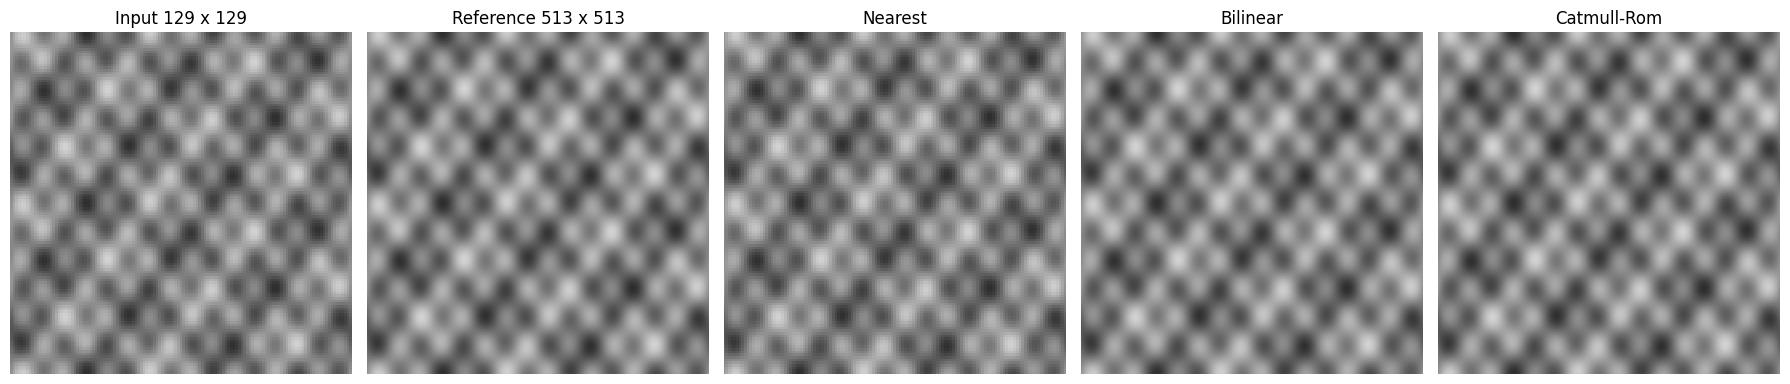


Interpolation error against the high-resolution reference:
Method                MAE       RMSE    PSNR (dB)
Nearest             2.793      3.635        36.92
Bilinear            0.380      0.630        52.14
Catmull-Rom         0.184      0.430        55.46


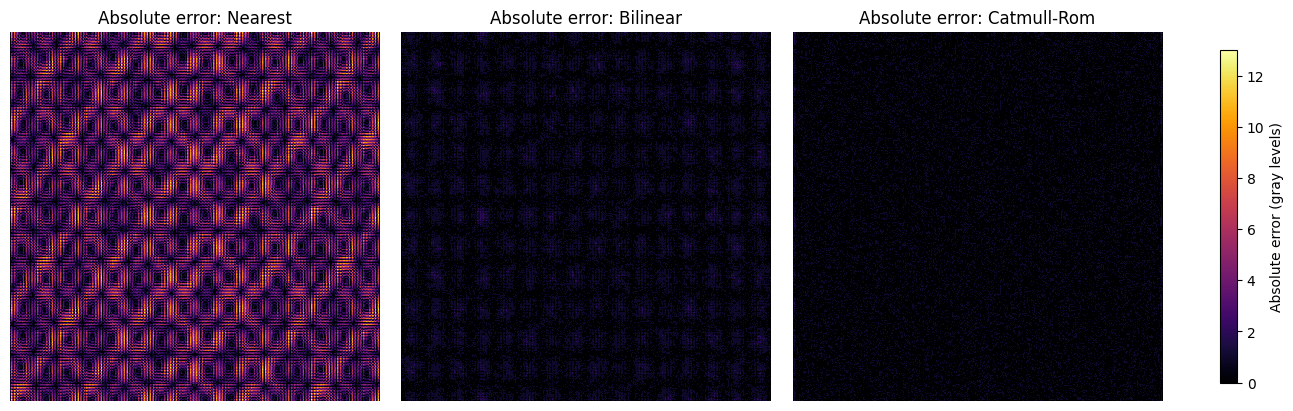

In [4]:
from pathlib import Path

input_image = low_resolution
output_names = ["nearest", "bilinear", "catmull_rom"]
titles = ["Nearest", "Bilinear", "Catmull-Rom"]
outputs = [np.fromfile(f"{name}.raw", dtype=np.uint8).reshape(HIGH_SIZE, HIGH_SIZE)
           for name in output_names]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(input_image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Input 129 x 129")
axes[1].imshow(reference, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[1].set_title("Reference 513 x 513")
for ax, result, title in zip(axes[2:], outputs, titles):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

errors = [result.astype(np.float64) - reference.astype(np.float64) for result in outputs]
print("\nInterpolation error against the high-resolution reference:")
print(f"{'Method':<14} {'MAE':>10} {'RMSE':>10} {'PSNR (dB)':>12}")
for title, error in zip(titles, errors):
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    psnr = float("inf") if rmse == 0 else 20.0 * np.log10(255.0 / rmse)
    print(f"{title:<14} {mae:10.3f} {rmse:10.3f} {psnr:12.2f}")

error_limit = max(1.0, max(float(np.max(np.abs(error))) for error in errors))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
error_images = []
for ax, error, title in zip(axes, errors, titles):
    error_image = ax.imshow(np.abs(error), cmap="inferno", vmin=0, vmax=error_limit,
                            interpolation="nearest")
    error_images.append(error_image)
    ax.set_title(f"Absolute error: {title}")
    ax.axis("off")
fig.colorbar(error_images[0], ax=axes, label="Absolute error (gray levels)", shrink=0.9)
plt.show()

### Interpreting the two comparisons

`validation PASS` means the GPU implementation agrees with the CPU implementation of the same interpolation rule. The MAE, RMSE, PSNR, and error maps instead compare each rule with the independently evaluated high-resolution image. Here, the known smooth pattern and its resolution pair make the interpolation errors measurable against ground truth. Images with sharp edges, fine detail, noise, or strong aliasing may produce a different ranking; Catmull--Rom is not guaranteed to be best for every image.